# 1. Imports y configuración

In [ ]:
#!{sys.executable} -m pip install mne

In [ ]:
from pathlib import Path
import sys
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import mne
import mlflow
import mlflow.pytorch
from mlflow.entities import ViewType
from mlflow.tracking import MlflowClient

# Proyecto
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta 'src' desde {Path.cwd()}"
    )

sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)

from src.models.cnn import TinySleepNet, TinySleepNetConfig


# Clases del modelo
CLASS_NAMES = ["W", "N1", "N2", "N3", "REM"]

# Parámetros de la señal
SAMPLING_RATE = 100
EPOCH_SECONDS = 30
SAMPLES_PER_EPOCH = SAMPLING_RATE * EPOCH_SECONDS
SEQ_LENGTH = 15

print("Samples por época:", SAMPLES_PER_EPOCH)
print("Épocas por secuencia:", SEQ_LENGTH)

PROJECT_ROOT: C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5
Samples por época: 3000
Épocas por secuencia: 15


# 2. Buscar los EDF

In [ ]:
DATA_DIR = PROJECT_ROOT / "data" / "sleep-edfx"

edf_files = list(DATA_DIR.rglob("*.edf"))

print(f"EDF encontrados: {len(edf_files)}")

for path in edf_files[:20]:
    print(path)

EDF encontrados: 394
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4001E0-PSG.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4001EC-Hypnogram.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4002E0-PSG.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4002EC-Hypnogram.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4011E0-PSG.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-soluciones-G5\data\sleep-edfx\sleep-cassette\SC4011EH-Hypnogram.edf
C:\Users\danos\Documents\MAIA\Cursos\Semestre 4\Proyecto DS\proyecto-desarrollo-de-solucion

# 3. Cargar un PSG

In [ ]:
PSG_PATH = edf_files[0]

raw = mne.io.read_raw_edf(
    PSG_PATH,
    preload=True,
    verbose=False
)

print(raw)
print("\nCanales:")
print(raw.ch_names)

C:\Users\danos\AppData\Local\Temp\ipykernel_23264\2796434259.py:3: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
C:\Users\danos\AppData\Local\Temp\ipykernel_23264\2796434259.py:3: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
C:\Users\danos\AppData\Local\Temp\ipykernel_23264\2796434259.py:3: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(


<RawEDF | SC4001E0-PSG.edf, 7 x 7950000 (79500.0 s), ~424.6 MiB, data loaded>

Canales:
['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']


# 4. Identificar Fpz-Cz

In [ ]:
fpz_cz_channels = [
    ch for ch in raw.ch_names
    if "Fpz-Cz" in ch or "FPZ-CZ" in ch.upper()
]

print(fpz_cz_channels)

['EEG Fpz-Cz']


In [ ]:
CHANNEL = fpz_cz_channels[0]
eog_channels = [ch for ch in raw.ch_names if 'EOG' in ch.upper()]
if not eog_channels:
    raise RuntimeError('No se encontró un canal EOG en el EDF.')
CHANNELS = [CHANNEL, eog_channels[0]]

eeg = raw.copy().pick(CHANNELS)

print(eeg)

<RawEDF | SC4001E0-PSG.edf, 2 x 7950000 (79500.0 s), ~121.3 MiB, data loaded>


# 5. Revisar la señal

Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


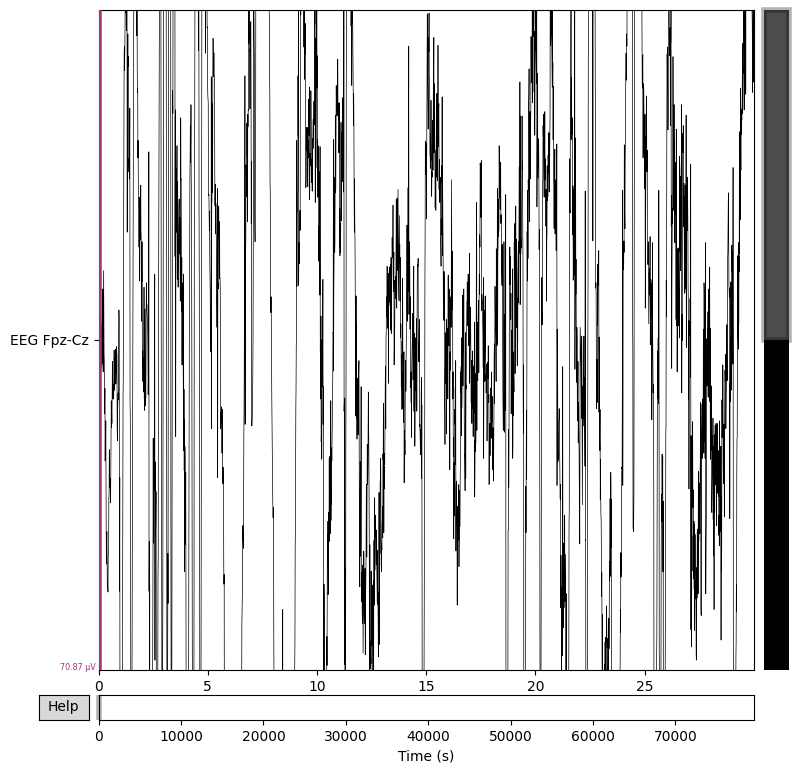

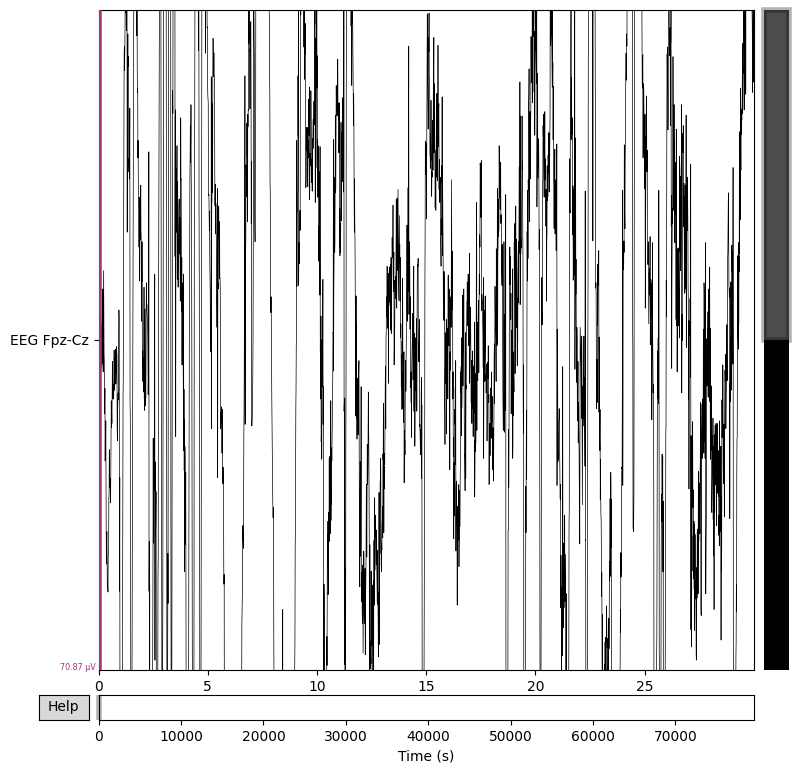

In [ ]:
eeg.plot(
    duration=30,
    n_channels=1,
    scalings="auto"
)

# 6. Asegurar 100 Hz

In [ ]:
print("Frecuencia original:", eeg.info["sfreq"])

Frecuencia original: 100.0


Si no fuera 100 Hz:

In [ ]:
if eeg.info["sfreq"] != SAMPLING_RATE:
    eeg.resample(SAMPLING_RATE)

In [ ]:
signal = eeg.get_data()

print("Shape:", signal.shape)
print("Frecuencia:", eeg.info["sfreq"])

Shape: (2, 7950000)
Frecuencia: 100.0


# 7. Dividir en épocas de 30 segundos

In [ ]:
n_epochs = signal.shape[1] // SAMPLES_PER_EPOCH

signal = signal[:, :n_epochs * SAMPLES_PER_EPOCH]

epochs = signal[:, :n_epochs * SAMPLES_PER_EPOCH].reshape(
    len(CHANNELS), n_epochs, SAMPLES_PER_EPOCH
).transpose(1, 0, 2)

print("Número de épocas:", epochs.shape[0])
print("Shape:", epochs.shape)

Número de épocas: 2650
Shape: (2650, 2, 3000)


# 8. Construir una secuencia de 15 épocas


In [ ]:
sequence = epochs[:SEQ_LENGTH]

print(sequence.shape)

(15, 2, 3000)


In [ ]:
x = torch.tensor(
    sequence,
    dtype=torch.float32
)

x = x.unsqueeze(0)

print(x.shape)

torch.Size([1, 15, 2, 3000])


# 9. Cargar el modelo desde MLflow

In [ ]:
MLFLOW_TRACKING_URI = os.getenv('MLFLOW_TRACKING_URI', 'http://32.194.151.154:5000')
MLFLOW_EXPERIMENT_ID = '2'
MLFLOW_ARTIFACT_PATH = os.getenv('MLFLOW_TINYSLEEPNET_ARTIFACT_PATH', 'tinysleepnet_final_eeg_eog.pth.zip')
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
client = MlflowClient()
runs = client.search_runs(
    experiment_ids=[MLFLOW_EXPERIMENT_ID],
    filter_string="attributes.status = 'FINISHED'",
    order_by=['attributes.start_time DESC'],
    max_results=100,
)
if not runs:
    raise FileNotFoundError('No hay runs finalizados en sleep-staging-advanced.')
RUN_ID = runs[0].info.run_id
MODEL_URI = f'runs:/{RUN_ID}/{MLFLOW_ARTIFACT_PATH}'
print('Run seleccionado:', RUN_ID)
print('Artefacto:', MODEL_URI)
checkpoint_path = mlflow.artifacts.download_artifacts(
    run_id=RUN_ID,
    artifact_path=MLFLOW_ARTIFACT_PATH,
)
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
print('Checkpoint:', type(checkpoint).__name__)


Run seleccionado: 6d1017859a1548c8939f488a91987a69
Artefacto: runs:/6d1017859a1548c8939f488a91987a69/tinysleepnet_final_eeg_eog.pth.zip


Checkpoint: OrderedDict


In [ ]:
config = TinySleepNetConfig(
    sampling_rate=SAMPLING_RATE,
    input_size=SAMPLES_PER_EPOCH,
    input_channels=len(CHANNELS),
    n_classes=len(CLASS_NAMES),
    seq_length=SEQ_LENGTH,
    use_rnn=True,
)
model = TinySleepNet(config)
if isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
    checkpoint = checkpoint['state_dict']
print('Parámetros del checkpoint:', len(checkpoint))
model.load_state_dict(checkpoint, strict=True)
model.eval()

Parámetros del checkpoint: 30


TinySleepNet(
  (cnn): TinySleepNetCNN(
    (block1): _ConvBNReLU(
      (conv): Conv1d(2, 128, kernel_size=(50,), stride=(6,), padding=(25,), bias=False)
      (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
    )
    (pool1): MaxPool1d(kernel_size=8, stride=8, padding=0, dilation=1, ceil_mode=False)
    (drop1): Dropout(p=0.5, inplace=False)
    (block2): Sequential(
      (0): _ConvBNReLU(
        (conv): Conv1d(128, 128, kernel_size=(8,), stride=(1,), padding=(4,), bias=False)
        (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
      )
      (1): _ConvBNReLU(
        (conv): Conv1d(128, 128, kernel_size=(8,), stride=(1,), padding=(4,), bias=False)
        (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
      )
      (2): _ConvBNReLU(
        (conv): Conv1d(128, 

# 10. Predicción

In [ ]:
with torch.no_grad():
    result, hidden = model.predict_proba(x)

In [ ]:
pred_classes = result["pred_class"][0]
confidences = result["confidence"][0]
probabilities = result["probabilities"][0]

In [ ]:
for i in range(SEQ_LENGTH):

    pred = pred_classes[i].item()
    confidence = confidences[i].item()

    print(
        f"Época {i+1:02d} | "
        f"{CLASS_NAMES[pred]:3s} | "
        f"Confianza: {confidence:.4f}"
    )

Época 01 | N2  | Confianza: 0.3460
Época 02 | N2  | Confianza: 0.4055
Época 03 | N2  | Confianza: 0.4412
Época 04 | N2  | Confianza: 0.4647
Época 05 | N2  | Confianza: 0.4821
Época 06 | N2  | Confianza: 0.4961
Época 07 | N2  | Confianza: 0.5078
Época 08 | N2  | Confianza: 0.5180
Época 09 | N2  | Confianza: 0.5270
Época 10 | N2  | Confianza: 0.5350
Época 11 | N2  | Confianza: 0.5422
Época 12 | N2  | Confianza: 0.5488
Época 13 | N2  | Confianza: 0.5549
Época 14 | N2  | Confianza: 0.5605
Época 15 | N2  | Confianza: 0.5657


# 11. Mostrar las probabilidades

In [ ]:
import pandas as pd

prob_array = probabilities.numpy()

prob_df = pd.DataFrame(
    prob_array,
    columns=CLASS_NAMES
)

prob_df.insert(
    0,
    "epoch",
    range(1, SEQ_LENGTH + 1)
)

prob_df["prediction"] = [
    CLASS_NAMES[p]
    for p in pred_classes.tolist()
]

prob_df["confidence"] = confidences.numpy()

prob_df

,epoch,W,N1,N2,N3,REM,prediction,confidence
0,1,0.041585,0.293939,0.346030,0.006757,0.311690,N2,0.346030
1,2,0.025656,0.275430,0.405541,0.003454,0.289918,N2,0.405541
2,3,0.020687,0.255377,0.441237,0.003078,0.279620,N2,0.441237
3,4,0.017931,0.240369,0.464720,0.003019,0.273961,N2,0.464720
4,5,0.016106,0.229623,0.482122,0.003007,0.269142,N2,0.482122
5,6,0.014797,0.221731,0.496079,0.002996,0.264396,N2,0.496079
6,7,0.013801,0.215597,0.507824,0.002980,0.259798,N2,0.507824
7,8,0.013005,0.210504,0.518001,0.002959,0.255530,N2,0.518001
8,9,0.012344,0.206021,0.526981,0.002935,0.251719,N2,0.526981
9,10,0.011779,0.201887,0.535004,0.002908,0.248422,N2,0.535004


In [ ]:
import requests
response = requests.post(
    'http://localhost:8000/predict',
    json={
        'channel_names': CHANNELS,
        'channel': 'EEG Fpz-Cz',
        'sampling_rate_hz': SAMPLING_RATE,
        'signal_unit': 'uV',
        'model_artifact': MLFLOW_ARTIFACT_PATH,
        'epochs': sequence.tolist(),
    },
)
response.raise_for_status()
api_result = response.json()
pd.DataFrame(api_result['predictions'])